In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score)

from scipy.cluster.hierarchy import linkage,dendrogram
df=pd.read_csv("Wholesale.csv")


In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.columns




Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

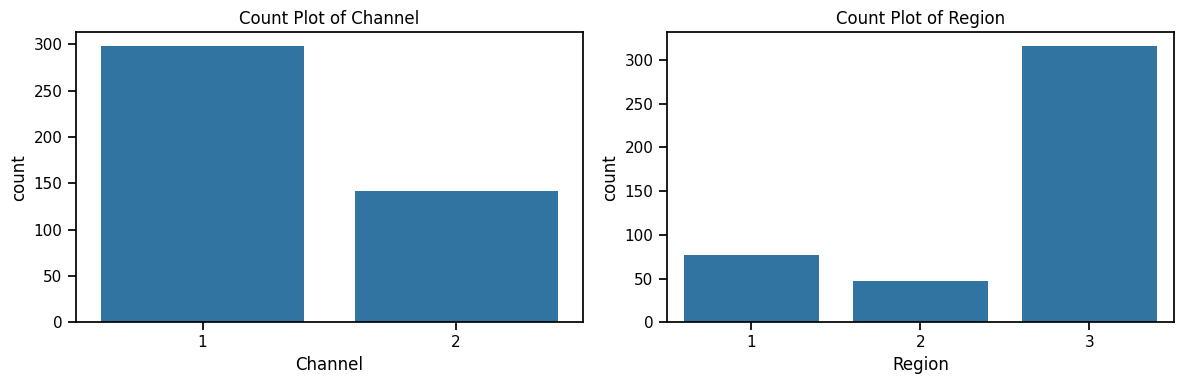

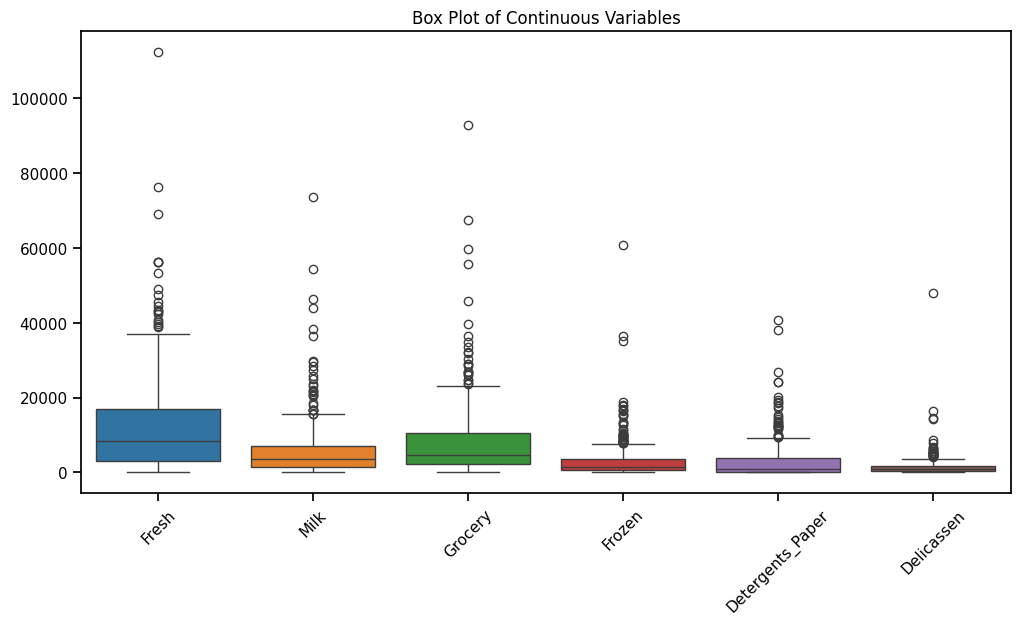

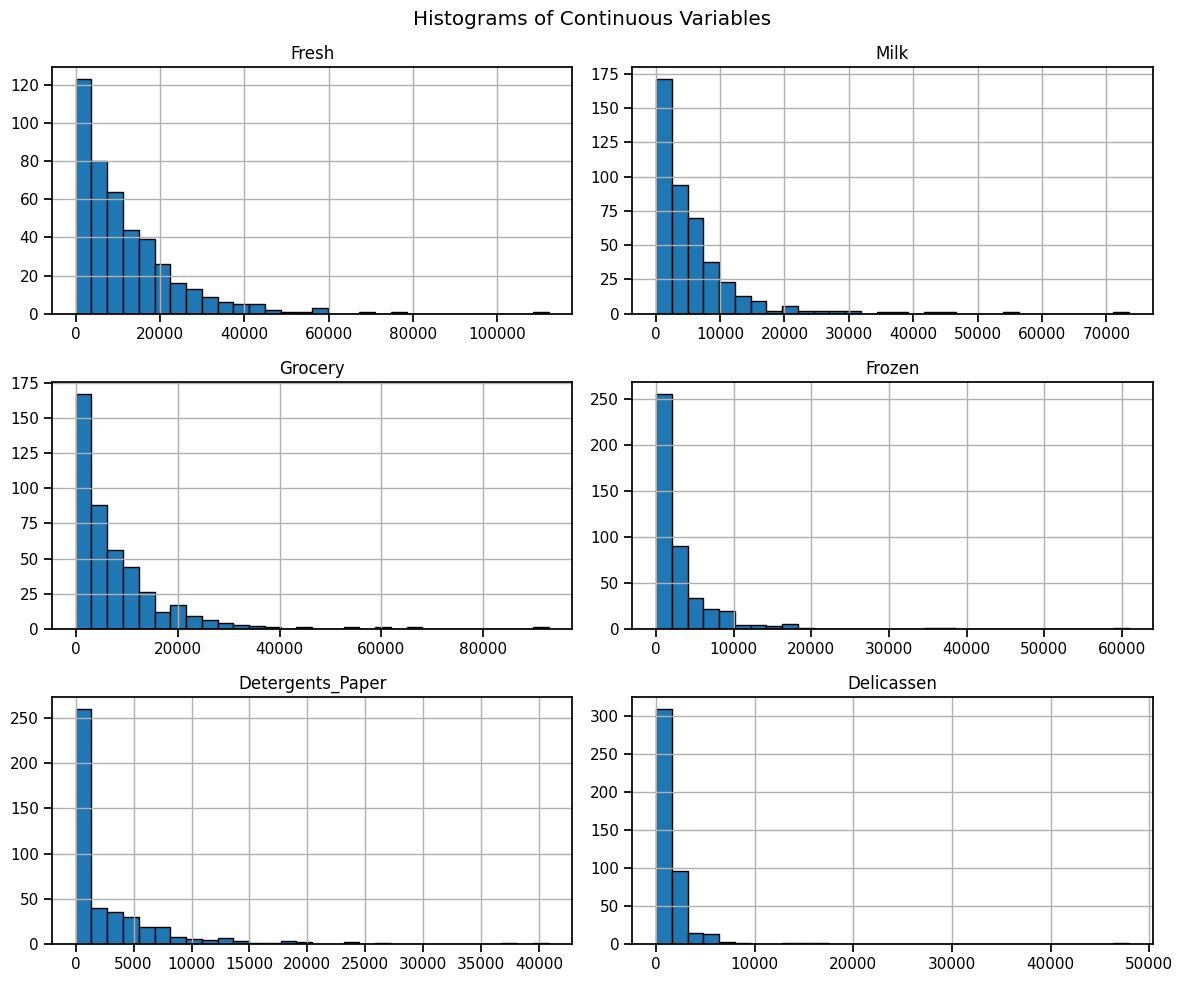

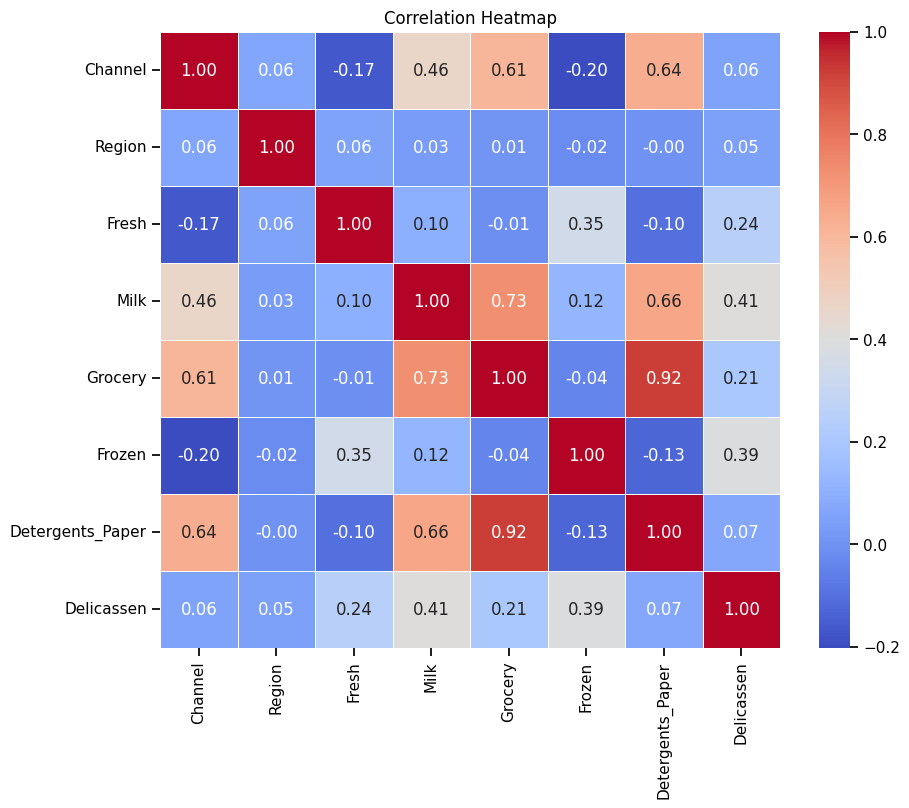

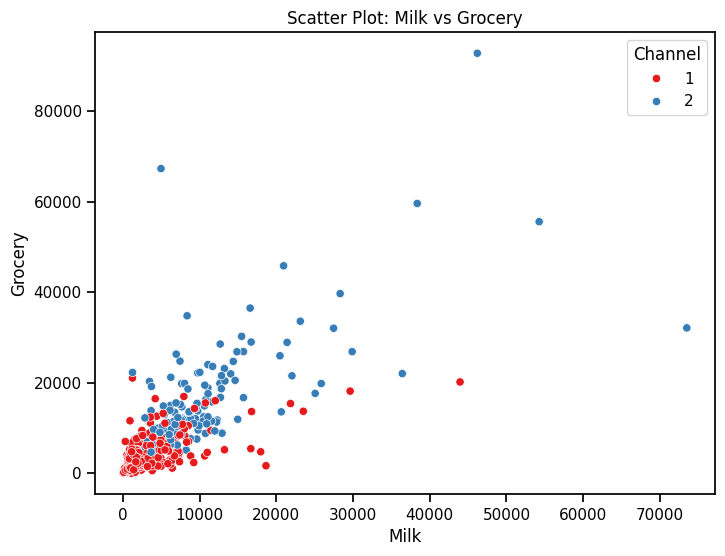

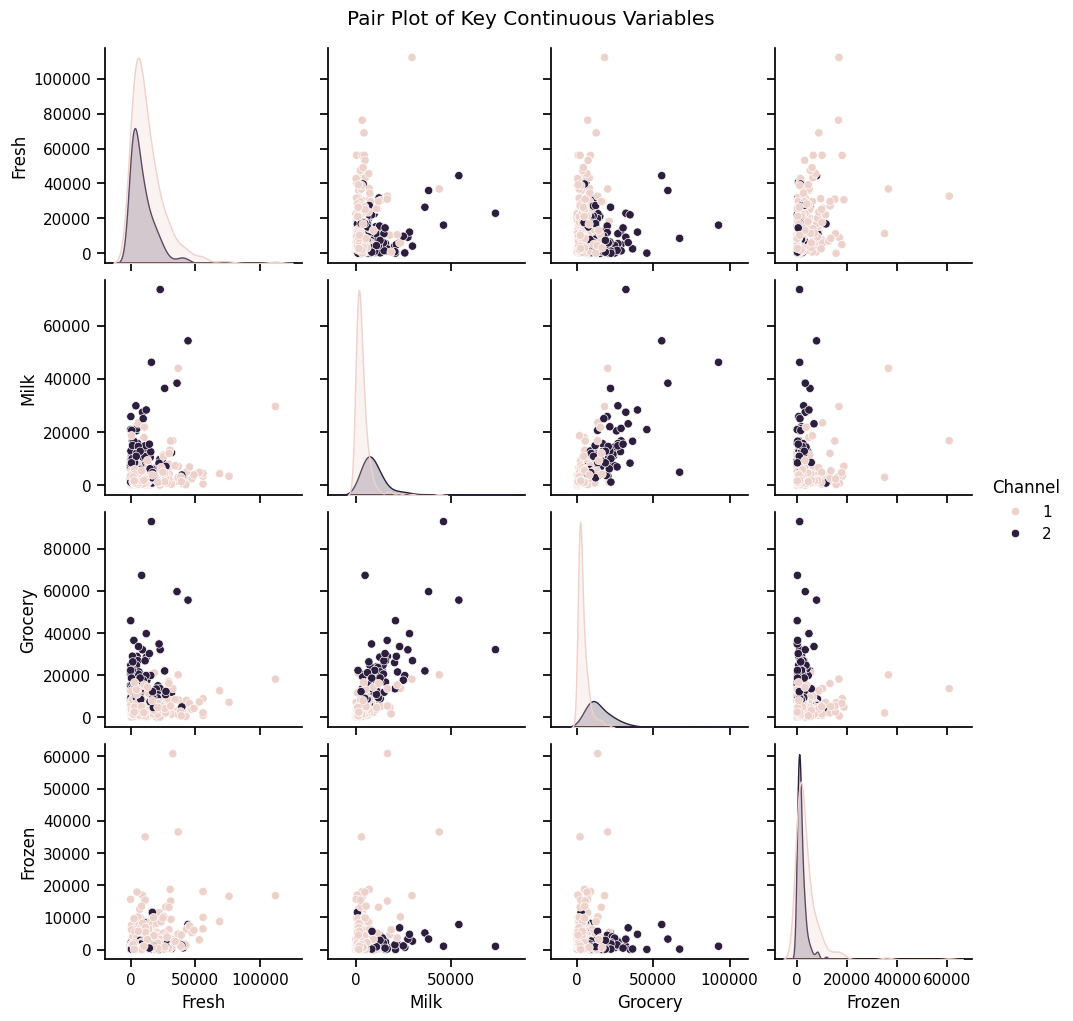

In [ ]:
# 1. Count Plots for Categorical Variables
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Channel', ax=axes[0])
axes[0].set_title('Count Plot of Channel')
sns.countplot(data=df, x='Region', ax=axes[1])
axes[1].set_title('Count Plot of Region')
plt.tight_layout()
plt.show()

# 2. Box Plots to check distributions and outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(['Channel', 'Region'], axis=1))
plt.title('Box Plot of Continuous Variables')
plt.xticks(rotation=45)
plt.show()

# 3. Histograms for Continuous Variables
df.drop(['Channel', 'Region'], axis=1).hist(figsize=(12, 10), bins=30, edgecolor='black')
plt.suptitle('Histograms of Continuous Variables')
plt.tight_layout()
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# 5. Scatter Plot (example: Milk vs Grocery colored by Channel)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Milk', y='Grocery', hue='Channel', palette='Set1')
plt.title('Scatter Plot: Milk vs Grocery')
plt.show()

# 6. Pair Plot of Selected Continuous Variables
sns.pairplot(df, vars=['Fresh', 'Milk', 'Grocery', 'Frozen'], hue='Channel')
plt.suptitle('Pair Plot of Key Continuous Variables', y=1.02)
plt.show()

In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

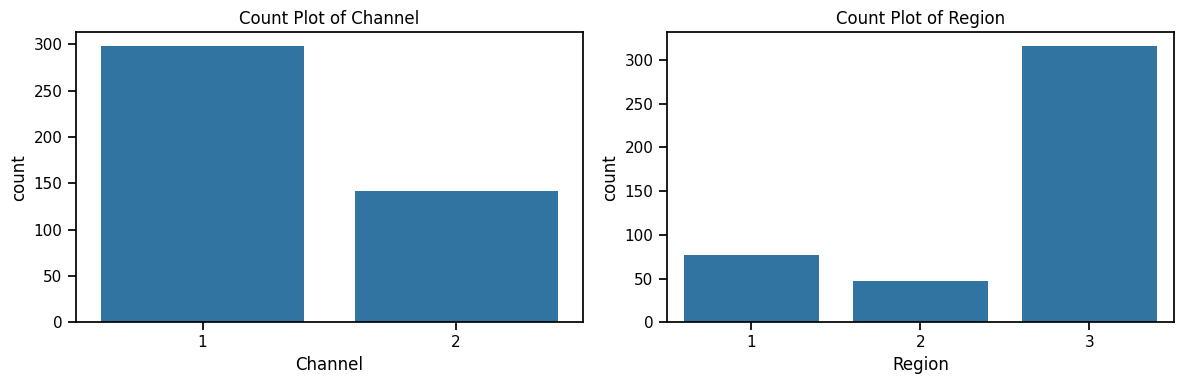

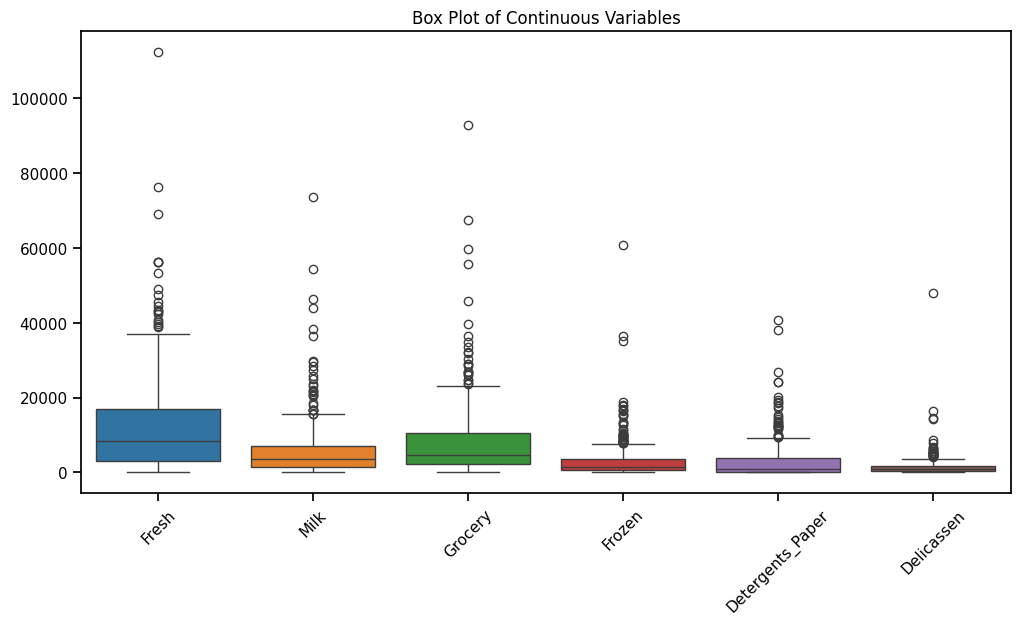

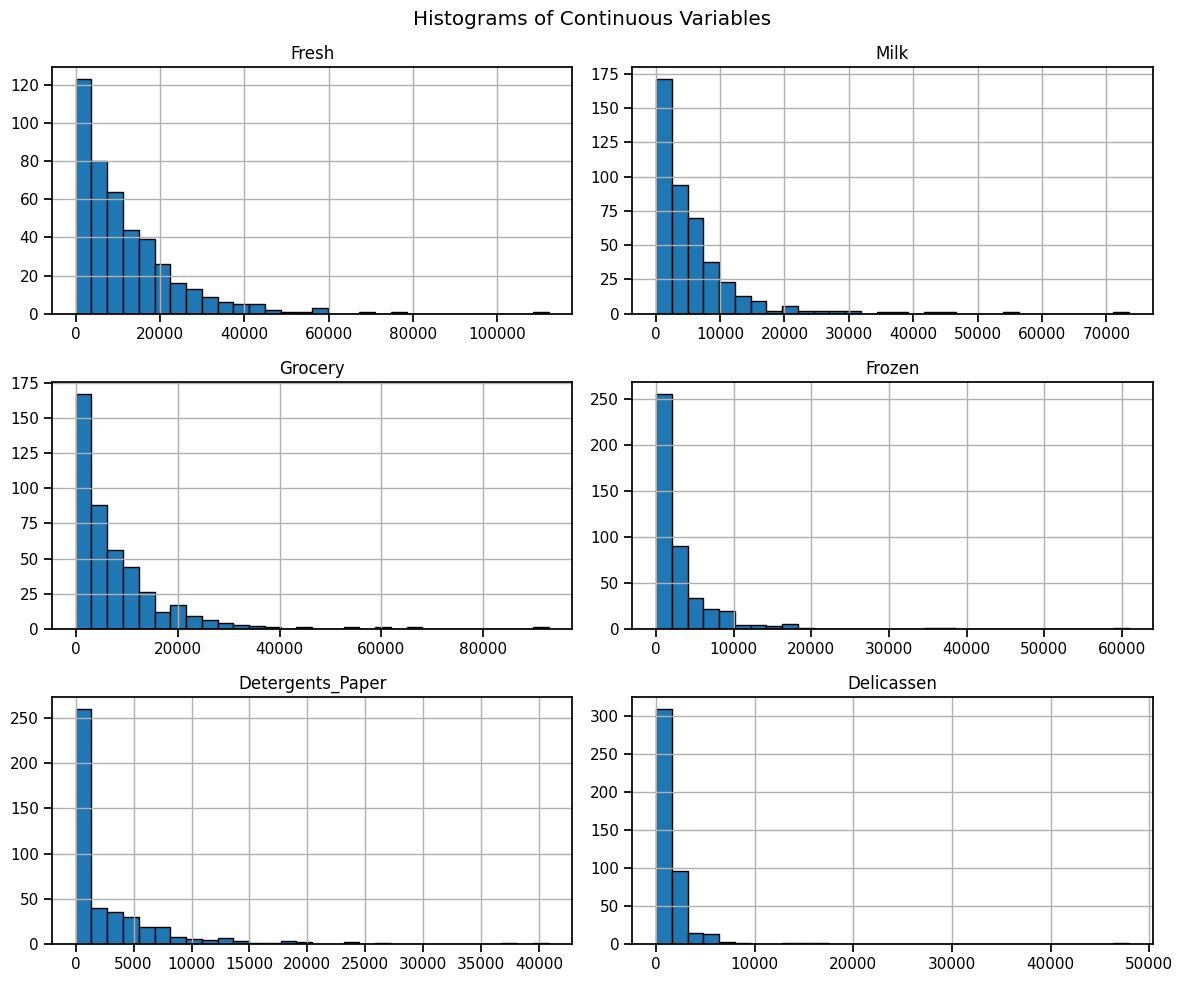

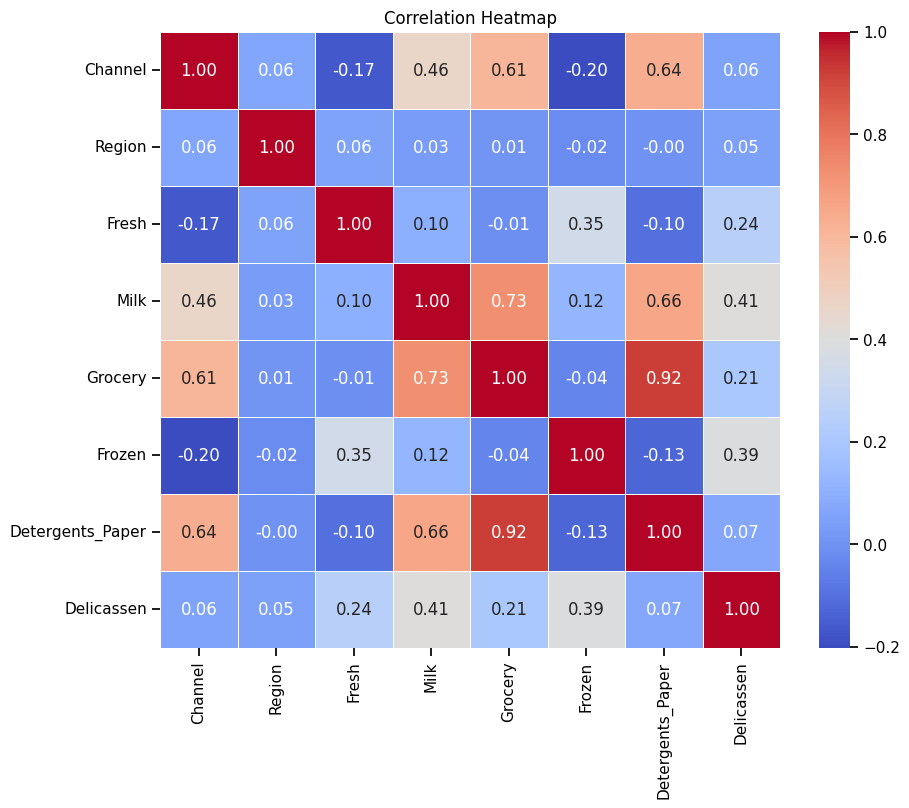

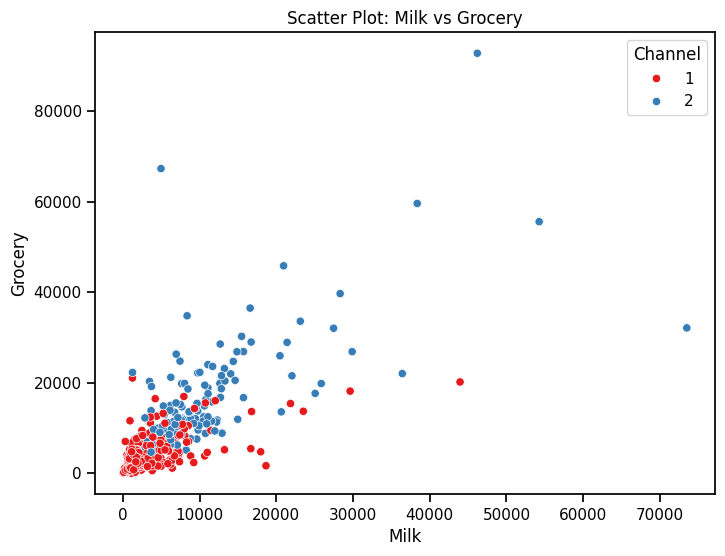

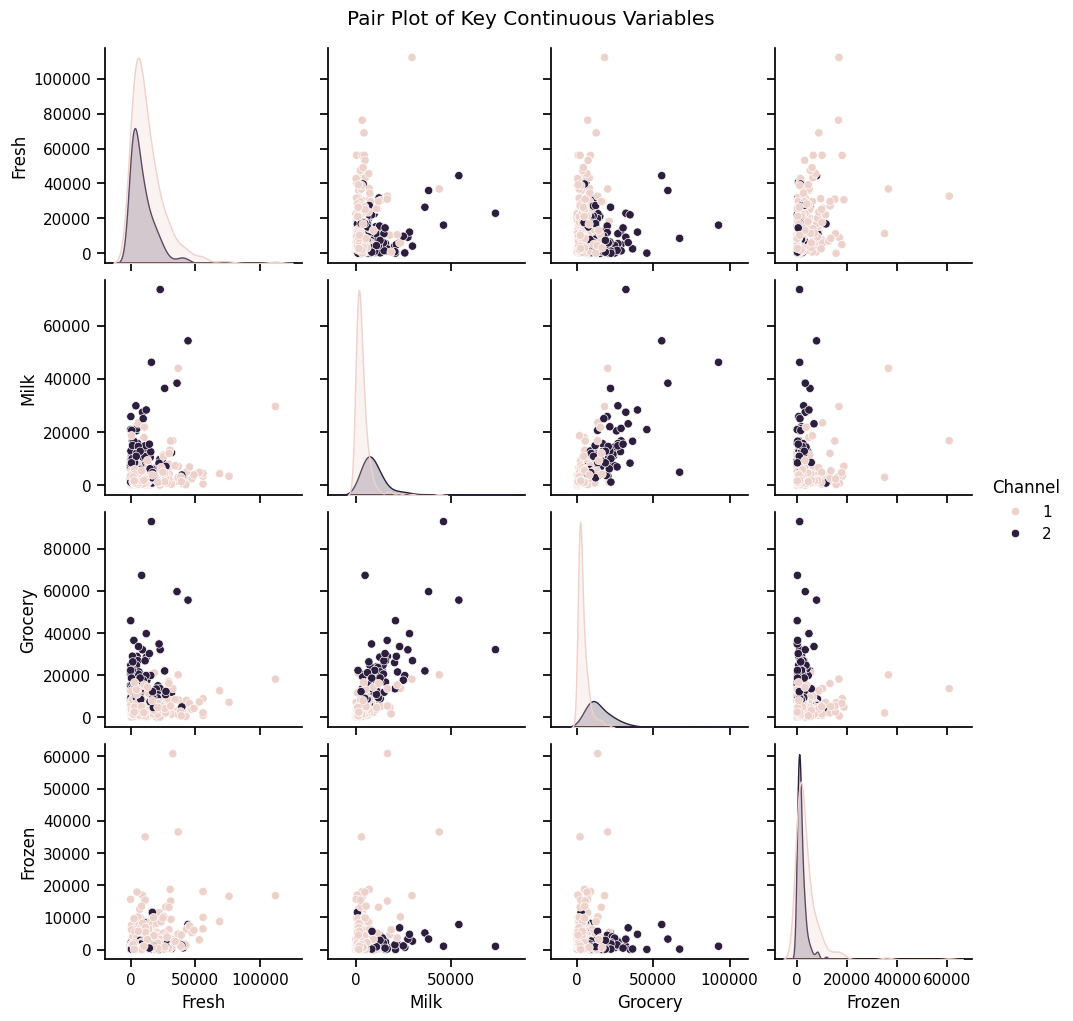

In [ ]:
# 1. Count Plots for Categorical Variables
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Channel', ax=axes[0])
axes[0].set_title('Count Plot of Channel')
sns.countplot(data=df, x='Region', ax=axes[1])
axes[1].set_title('Count Plot of Region')
plt.tight_layout()
plt.show()

# 2. Box Plots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(['Channel', 'Region'], axis=1))
plt.title('Box Plot of Continuous Variables')
plt.xticks(rotation=45)
plt.show()

# 3. Histograms
df.drop(['Channel', 'Region'], axis=1).hist(figsize=(12, 10), bins=30, edgecolor='black')
plt.suptitle('Histograms of Continuous Variables')
plt.tight_layout()
plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# 5. Scatter Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Milk', y='Grocery', hue='Channel', palette='Set1')
plt.title('Scatter Plot: Milk vs Grocery')
plt.show()

# 6. Pair Plot
sns.pairplot(df, vars=['Fresh', 'Milk', 'Grocery', 'Frozen'], hue='Channel')
plt.suptitle('Pair Plot of Key Continuous Variables', y=1.02)
plt.show()

In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)

In [ ]:
X_scaled_df=pd.DataFrame(X_scaled,columns=df.columns,index=df.index)
print("First Five Scaled Records:")
display(X_scaled_df.head())

First Five Scaled Records:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


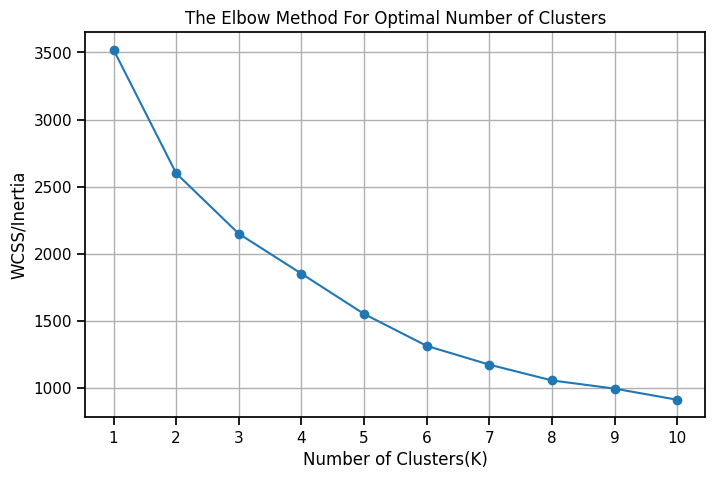

In [ ]:
wcss=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker='o')
plt.title('The Elbow Method For Optimal Number of Clusters')
plt.xlabel('Number of Clusters(K)')
plt.ylabel('WCSS/Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [ ]:
silhouette_values = []
k_values_silhouette = range(2, 11)
for k in k_values_silhouette:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhoutte_table = pd.DataFrame({
    "Number of Clusters": list(k_values_silhouette),
    "Silhouette Score": silhouette_values
})
display(silhoutte_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.3734
1,3,0.3568
2,4,0.3482
3,5,0.3529
4,6,0.3526
5,7,0.3638
6,8,0.3743
7,9,0.3081
8,10,0.3310


Variance explained by the two PCA components: 61.12 %


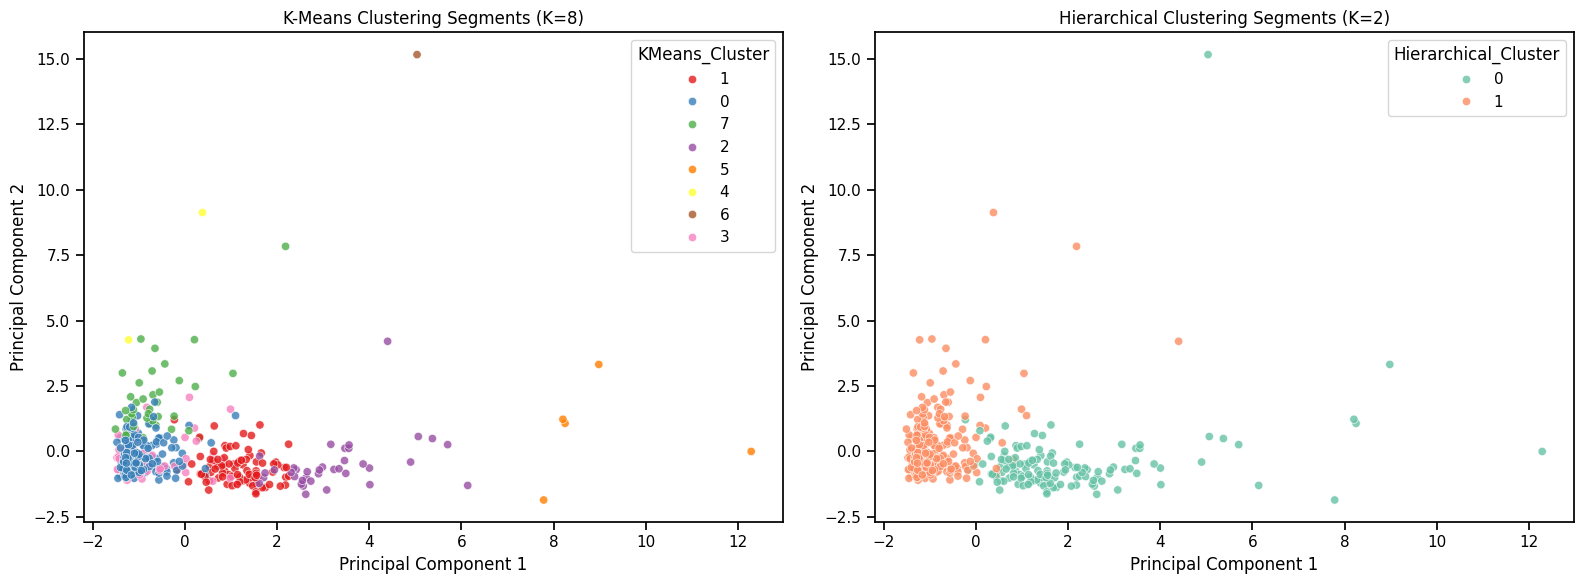

In [ ]:
# 1. Properly fit K-Means with K=8 and extract labels
kmeans_model = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Add labels to original dataframe copy
df_Kmeans = df.copy()
df_Kmeans["KMeans_Cluster"] = kmeans_labels

# 2. Fit Agglomerative Hierarchical Clustering
# The dendrogram suggests 2 main branches (highest vertical distance)
hier_model = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
hier_labels = hier_model.fit_predict(X_scaled)

# Add labels to original dataframe copy
df_Kmeans["Hierarchical_Cluster"] = hier_labels

# 3. PCA Projection for 2D Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the two PCA components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Create a visualization dataframe
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels.astype(str),
    "Hierarchical_Cluster": hier_labels.astype(str)
})

# 4. Visualization of Customer Segments
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=plot_df, x="PC1", y="PC2", hue="KMeans_Cluster",
    palette="Set1", ax=axes[0], alpha=0.8
)
axes[0].set_title("K-Means Clustering Segments (K=8)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

sns.scatterplot(
    data=plot_df, x="PC1", y="PC2", hue="Hierarchical_Cluster",
    palette="Set2", ax=axes[1], alpha=0.8
)
axes[1].set_title("Hierarchical Clustering Segments (K=2)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [ ]:
# Properly fit K-Means with K=8 and extract the cluster labels
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [ ]:
df_Kmeans=df.copy()
df_Kmeans["KMeans_Cluster"]=kmeans_labels
print("K-means clustering completed.")
print("\n Number of Customers in each Cluster")
print(df_Kmeans["KMeans_Cluster"].value_counts().sort_index)
print("\n Sample records with cluster labels:")
display(df_Kmeans.head())

K-means clustering completed.

 Number of Customers in each Cluster
<bound method Series.sort_index of KMeans_Cluster
KMeans(n_init=10, random_state=42)    440
Name: count, dtype: int64>

 Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,"KMeans(n_init=10, random_state=42)"
1,2,3,7057,9810,9568,1762,3293,1776,"KMeans(n_init=10, random_state=42)"
2,2,3,6353,8808,7684,2405,3516,7844,"KMeans(n_init=10, random_state=42)"
3,1,3,13265,1196,4221,6404,507,1788,"KMeans(n_init=10, random_state=42)"
4,2,3,22615,5410,7198,3915,1777,5185,"KMeans(n_init=10, random_state=42)"


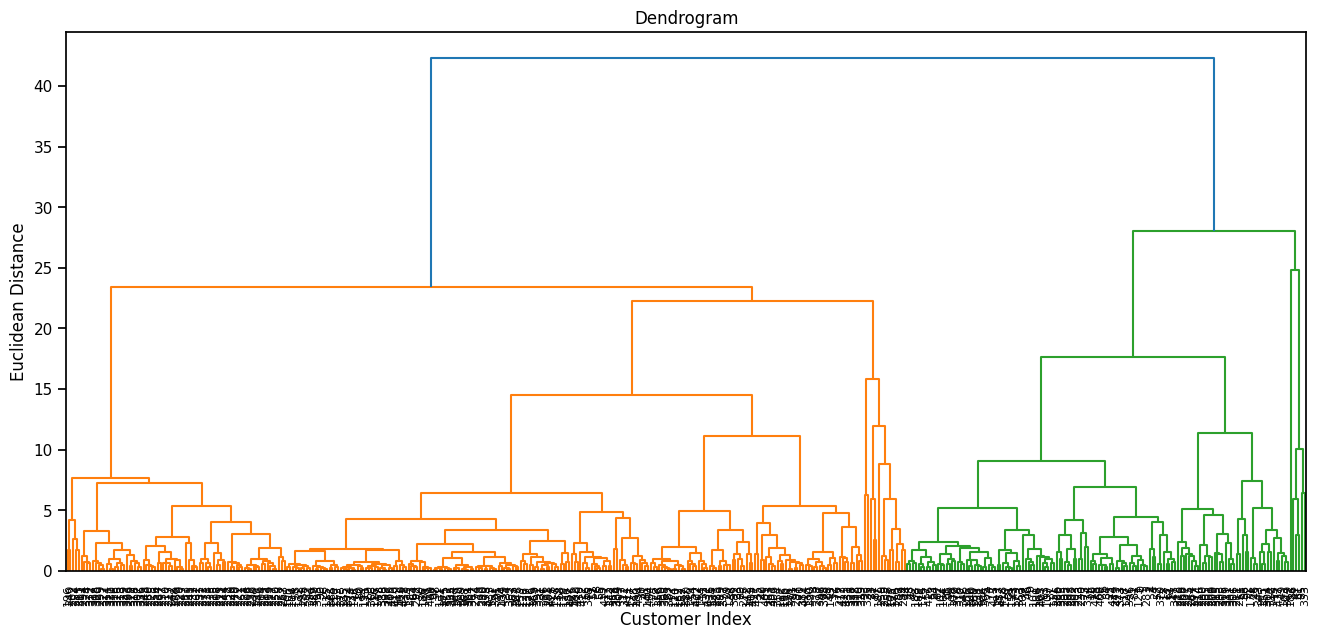

In [ ]:
Z=linkage(X_scaled,method="ward",metric="euclidean")
plt.figure(figsize=(16,7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram")
plt.xlabel("Customer Index")
plt.ylabel("Euclidean Distance")
plt.show()

Text(0, 0.5, 'Euclidean Distance')

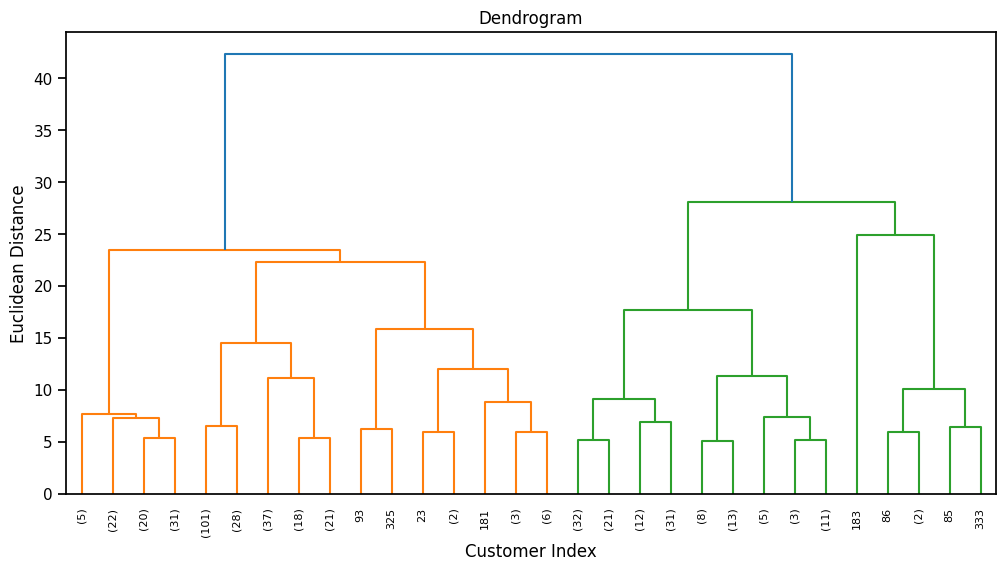

In [ ]:
plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode="lastp",leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram")
plt.xlabel("Customer Index")
plt.ylabel("Euclidean Distance")

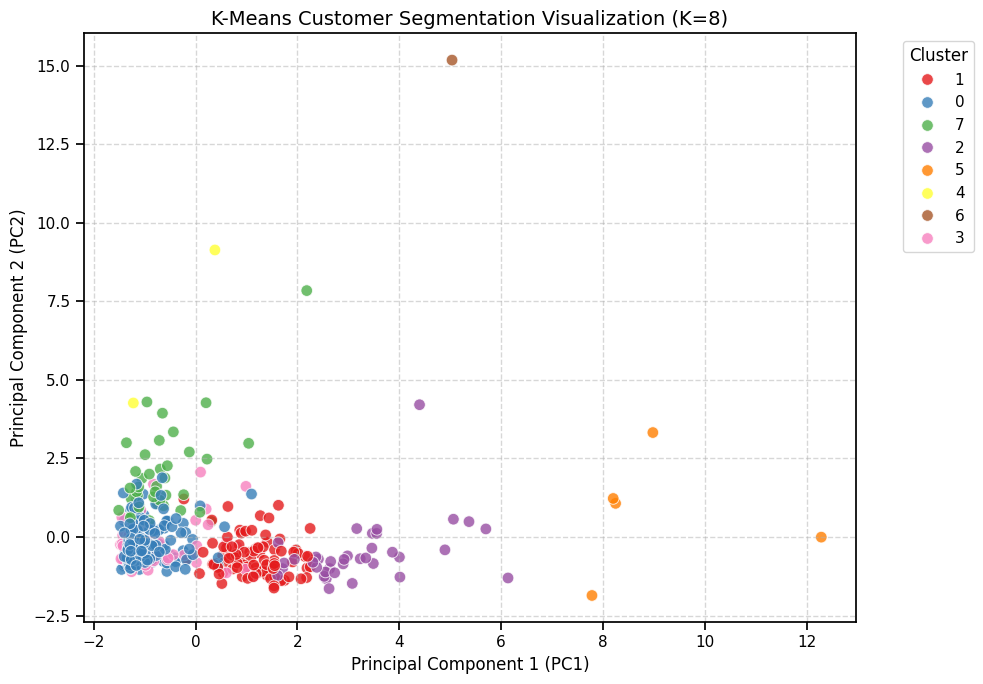

In [ ]:
bb# Append labels to the dataset for profiling
df_Kmeans = df.copy()
df_Kmeans["KMeans_Cluster"] = kmeans_labels

# Project high-dimensional customer features into 2D via PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a visualization DataFrame
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels.astype(str)
})

# Plot the customer segments
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set1",
    alpha=0.8,
    edgecolor='w',
    s=70
)
plt.title(f"K-Means Customer Segmentation Visualization (K={K})", fontsize=14)
plt.xlabel("Principal Component 1 (PC1)", fontsize=12)
plt.ylabel("Principal Component 2 (PC2)", fontsize=12)
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data,labels,model_name):
  return{
      "Algorithm":model_name,
      "Silhouette Score":silhouette_score(X_data,labels),
      "Davies-Bouldin Score":davies_bouldin_score(X_data,labels),
  }

In [ ]:
from sklearn.metrics import davies_bouldin_score

comparision=pd.DataFrame([evaluate_clustering(X_scaled,kmeans_labels,"KMeans"),
                          evaluate_clustering(X_scaled,hier_labels,"Hierarchical")])
print("Comparision of clustering Algorithms:")
display(comparision.round(4))

Comparision of clustering Algorithms:


,Algorithm,Silhouette Score,Davies-Bouldin Score
0,KMeans,0.3743,0.937
1,Hierarchical,0.3680,1.285


In [ ]:
# Fix: ensure Hierarchical_Cluster is added back to the dataframe copy
df_Kmeans["Hierarchical_Cluster"] = hier_labels

cluster_sizes=pd.DataFrame({
    "K-Means":df_Kmeans["KMeans_Cluster"].value_counts().sort_index(),
    "Hierarchical":df_Kmeans["Hierarchical_Cluster"].value_counts().sort_index()
})
print("Cluster Sizes:")
display(cluster_sizes)

Cluster Sizes:


,K-Means,Hierarchical
0,201,142.0
1,92,298.0
2,37,NaN
3,61,NaN
4,2,NaN
5,5,NaN
6,1,NaN
7,41,NaN


In [ ]:
# Define the continuous spending features to analyze
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

kmeans_profile=df[features].copy()
kmeans_profile["Cluster"]=kmeans_labels
kmeans_means=kmeans_profile.groupby("Cluster")[features].mean().round(2)
print("Average spending profile for each cluster:")
display(kmeans_means)

Average spending profile for each cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,8988.70,2796.09,3487.16,2816.39,733.18,1002.09
1,8731.82,7392.77,11361.22,1475.26,4698.03,1449.65
2,5694.54,15773.59,24499.59,1707.92,11545.19,2463.08
3,10095.11,3965.02,4382.66,2816.43,1191.66,1127.75
4,22015.50,9937.00,7844.00,47939.00,671.50,4153.50
5,25603.00,43460.60,61472.20,2636.00,29974.20,2708.80
6,36847.00,43950.00,20170.00,36534.00,239.00,47943.00
7,39870.29,4916.85,5740.59,6566.93,901.27,2595.95
